# US used-car listings · pipeline walkthrough

**PySpark · SQL · Parquet · data quality · MLlib · MongoDB**

This notebook presents the maintained Python package. Its default run uses **synthetic data**, not a Kaggle subset. Full-data results are reviewed by setting `CARS_RUN_DIR` to an existing Kaggle run directory before starting the kernel.

The analytical target is an advertised **asking price in USD**. Mileage uses **miles**. Inventory listings are not completed transactions.

In [1]:
import json
import os
from importlib.resources import files
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

PROJECT_ROOT = next(
    path for path in (Path.cwd(), *Path.cwd().parents) if (path / "pyproject.toml").exists()
)
RUN_DIR = PROJECT_ROOT / os.environ.get("CARS_RUN_DIR", "outputs/demo")
print("Run directory:", RUN_DIR.relative_to(PROJECT_ROOT))

Run directory: outputs/demo


## 1. Run or reuse the package pipeline

The CSV parser validates the 66-column header and handles quoted commas, quotes and newlines. Bronze keeps source strings; silver contains typed, scoped, deduplicated used listings. Quarantine explains excluded records. Existing completed outputs are reused.

In [2]:
from used_cars.analysis import analyze
from used_cars.config import Settings, settings_from_manifest
from used_cars.demo import generate_demo
from used_cars.etl import ingest
from used_cars.spark import create_spark

if (RUN_DIR / "manifest.json").exists():
    settings = settings_from_manifest(RUN_DIR)
else:
    settings = Settings(output=RUN_DIR, dataset_kind="synthetic", run_id="notebook-demo")
spark = create_spark(settings)
if not (RUN_DIR / "manifest.json").exists():
    source = PROJECT_ROOT / "data/demo/used_cars_data.csv"
    if not source.exists():
        generate_demo(source)
    ingest(spark, source, settings)
if not (RUN_DIR / "results.json").exists():
    analyze(spark, settings)
manifest = json.loads((RUN_DIR / "manifest.json").read_text())
results = json.loads((RUN_DIR / "results.json").read_text())
print("DATASET KIND:", manifest["dataset_kind"].upper())
print("Input bytes:", manifest["source"]["bytes"])
print("SHA-256:", manifest["source"]["sha256"])

DATASET KIND: SYNTHETIC
Input bytes: 249337
SHA-256: dc6dd985c37bac9d5b6f055e639275fdbcfed32a0c3afc78a78d08abda904c77


## 2. Account for every source row

Invalid, out-of-scope and duplicate rows are distinct dispositions. New vehicles are out of scope. Missing horsepower is retained and later imputed from train. Plausible extreme values are flagged rather than silently removed. Primary reasons below are mutually exclusive.

In [3]:
quality = results["quality"]
counts = {
    name: quality[name]
    for name in ["input_rows", "invalid_rows", "out_of_scope_rows", "duplicate_rows", "silver_rows"]
}
display(pd.DataFrame(counts.items(), columns=["disposition", "rows"]))
assert quality["input_rows"] == sum(
    quality[name] for name in ["invalid_rows", "out_of_scope_rows", "duplicate_rows", "silver_rows"]
)
display(pd.DataFrame(quality["primary_dispositions"]))

,disposition,rows
0,input_rows,1200
1,invalid_rows,48
2,out_of_scope_rows,36
3,duplicate_rows,12
4,silver_rows,1104


,route,primary_reason,count
0,duplicate,duplicate_listing,12
1,invalid,invalid_mileage,12
2,invalid,invalid_price,12
3,invalid,missing_make,12
4,invalid,unknown_new_flag,12
5,out_of_scope,new_vehicle,12
6,out_of_scope,price_below_scope,12
7,out_of_scope,year_outside_scope,12


## 3. Query the persisted silver layer with Spark SQL

Only bounded aggregate results are converted to pandas. The source CSV is never loaded into pandas. The SQL below is the same versioned query used by the CLI.

In [4]:
silver = spark.read.parquet(str(RUN_DIR / "silver"))
silver.createOrReplaceTempView("cars")
query = files("used_cars").joinpath("sql/by_make.sql").read_text()
print(query)
display(spark.sql(query).toPandas())

SELECT make_name, COUNT(*) AS listings,
       AVG(price) AS mean_price_usd,
       PERCENTILE_APPROX(price, 0.5, 10000) AS median_price_usd,
       AVG(mileage) AS mean_mileage_miles
FROM cars
GROUP BY make_name
ORDER BY listings DESC, make_name
LIMIT 20



,make_name,listings,mean_price_usd,median_price_usd,mean_mileage_miles
0,CHEVROLET,235,27042.531915,28068.0,93532.012766
1,HONDA,232,29046.228448,29649.0,88239.000000
2,FORD,216,27501.777778,26893.0,85860.199074
3,BMW,214,35680.906542,35675.0,95391.457944
4,TOYOTA,207,29688.082126,29865.0,95399.115942


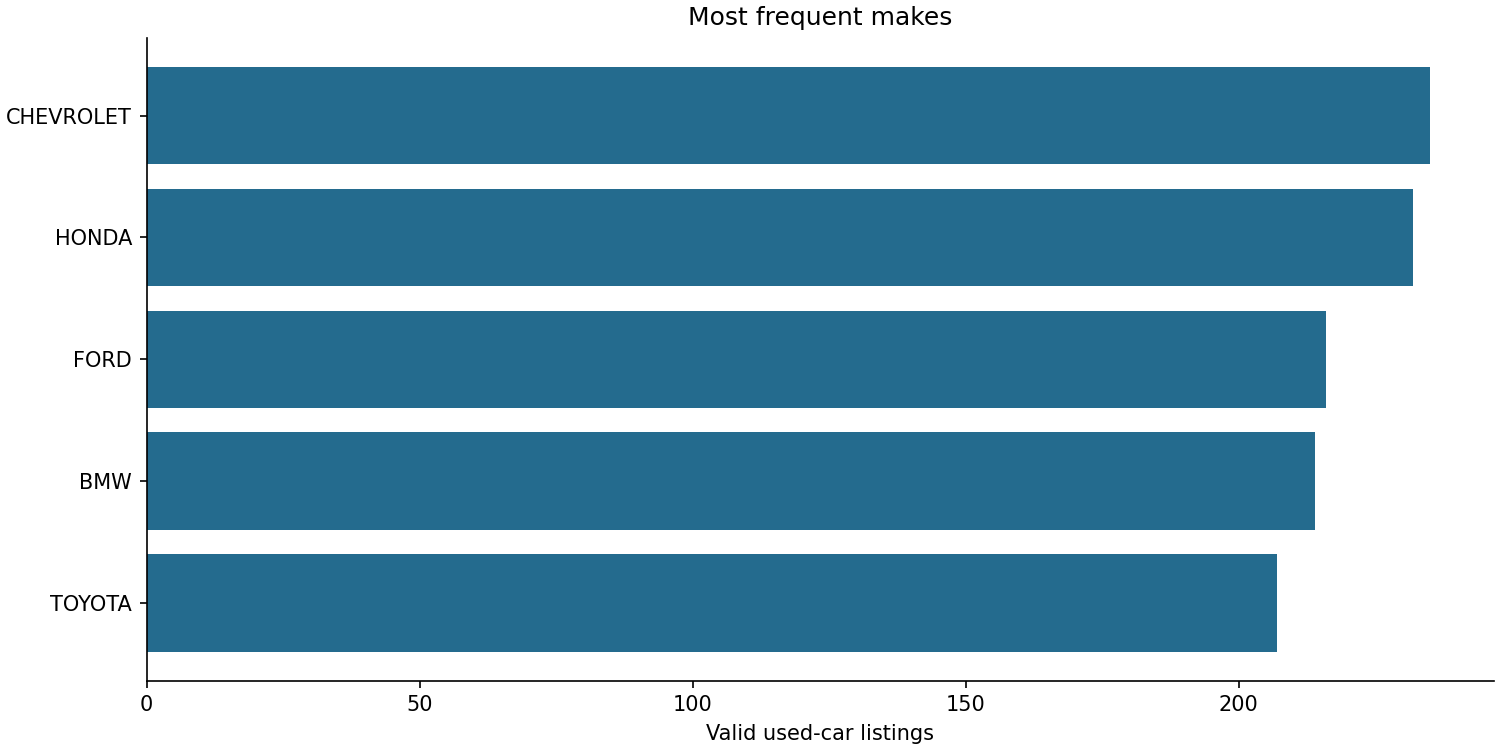

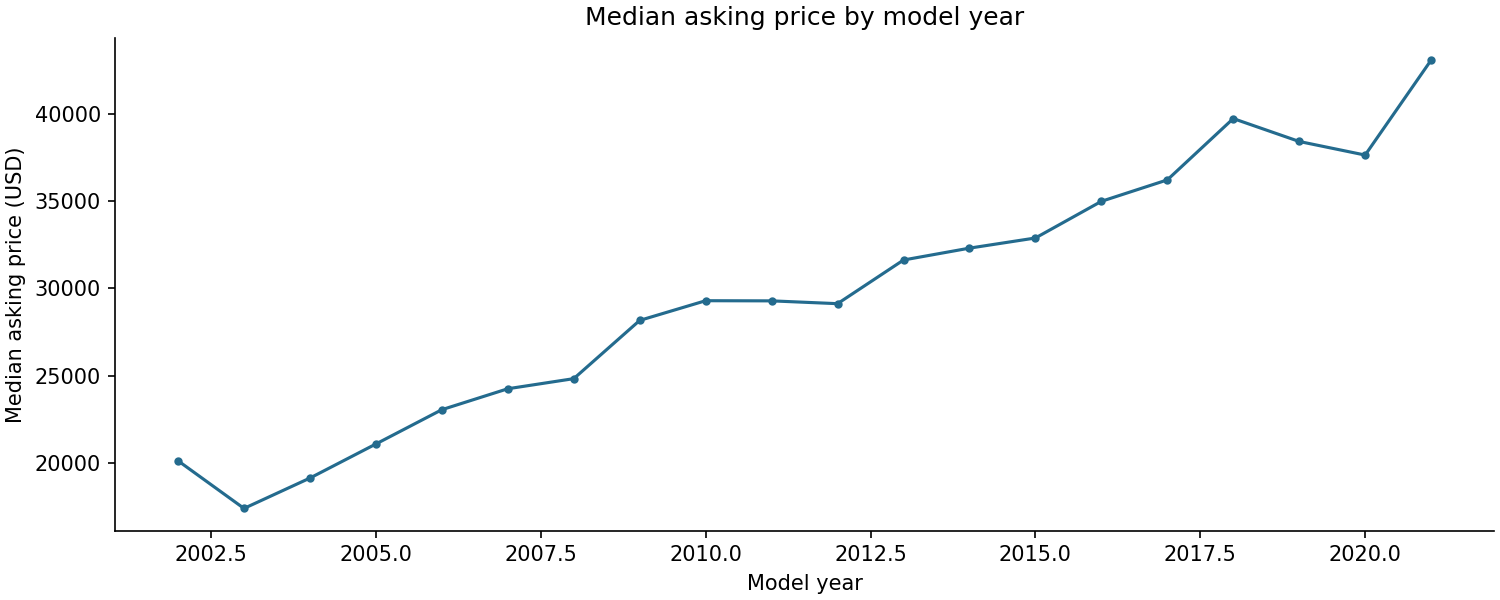

In [5]:
display(Image(filename=str(RUN_DIR / "report/top_makes.png")))
display(Image(filename=str(RUN_DIR / "report/prices_by_year.png")))

## 4. Estimate asking prices with a held-out group split

Vehicle-key hashing keeps usable VIN groups within one partition (approximately 70% train, 15% validation, 15% test). Missing VINs use a listing/hash fallback. Imputation and nominal one-hot encoding are fitted on train only. Validation RMSE selects between ridge and two GBT candidates; the selected model is then evaluated on test. The baseline predicts the training mean.

**Synthetic-run metrics validate execution; they are not evidence of real-market predictive accuracy.**

In [6]:
if "models" in results:
    regression = results["models"]["regression"]
    display(pd.DataFrame(regression["split_rows"].items(), columns=["partition", "rows"]))
    display(
        pd.DataFrame(
            [
                {"model": "train_mean_baseline", **regression["baseline"]["test"]},
                {"model": regression["selected_model"], **regression["test"]},
            ]
        )
    )
else:
    print("ML was skipped for this run.")

,partition,rows
0,test,158
1,validation,171
2,train,775


,model,rows,mae_usd,rmse_usd,r2
0,train_mean_baseline,158,7542.725815,9134.888236,-0.002047
1,ridge,158,1293.143538,1689.516345,0.965723


## 5. Describe exploratory market segments

K-Means uses standardized price, mileage and model year. In-sample squared-Euclidean silhouette chooses among a small set of k values. The segments are descriptive, not independently validated customer or risk groups; their numeric labels are arbitrary.

In [7]:
if "models" in results:
    clustering = results["models"]["clustering"]
    display(pd.DataFrame(clustering["candidates"]))
    display(pd.DataFrame(clustering["clusters"]))

,k,silhouette_squared_euclidean
0,3,0.614883
1,4,0.543570
2,5,0.483932


,cluster,listings,mean_price_usd,mean_mileage_miles,mean_model_year
0,0,382,20835.018325,156020.764398,2005.196335
1,1,345,38886.591304,25930.921739,2018.147826
2,2,377,30345.888594,86505.472149,2011.496021


## 6. Publish and reproduce

The CLI can upsert these bounded summaries into MongoDB using stable `(run_id, section)` identities. It never deletes the entire results collection. `MONGO_URI` is read from the environment.

- Reproduce the default example: `cars demo`, then the `cars run ... --dataset-kind synthetic` command in the README.
- Download the real 9.98 GB file separately with `cars download` and run the full-data command.
- Inspect the standalone report at `outputs/<run>/report/index.html`.
- Inspect the input hash, software versions, model fraction and timings in the run manifest.

The full dataset is historical September 2020 inventory, not current transaction data. See the README and engineering decisions for population and validation limitations.

In [8]:
spark.stop()